# Lab 2: Classification Using KNN and RNN Algorithms

**Name:** Sai Sravani P
**Course:** MSCS 634 – Advanced Big Data and Data Mining
**Lab Assignment:** Lab 2 – K-Nearest Neighbors (KNN) and Radius Neighbors (RNN) on the Wine Dataset

---

In this lab I use the Wine Dataset to train KNN and Radius Neighbors classifiers, test different values of k and
radius, and compare how accuracy changes.

## Step 1: Load and Prepare the Dataset

### 1.1 Imports
Importing the libraries needed for this lab. I set a random state so the results are the same every time.

In [1]:
# Core data handling
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Dataset, splitting, models, and evaluation
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier, RadiusNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

RANDOM_STATE = 42          # fixed seed for a reproducible train/test split
sns.set_theme(style="whitegrid")

### 1.2 Load the Wine Dataset
The dataset has 178 wine samples, 13 chemical features, and 3 classes.

In [2]:
wine = load_wine()

# Put features and target into a DataFrame for easier exploration
df = pd.DataFrame(wine.data, columns=wine.feature_names)
df["target"] = wine.target

print(f"Shape: {df.shape[0]} samples x {df.shape[1] - 1} features")
print("Classes:", list(wine.target_names))
df.head()

Shape: 178 samples x 13 features
Classes: [np.str_('class_0'), np.str_('class_1'), np.str_('class_2')]


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


### 1.3 Basic Data Exploration
Checking the data types, missing values, basic statistics, and class distribution.

In [3]:
# Data types and non-null counts
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 non-null    float64
 12  proline                       178 non-null    float64
 13  target          

In [4]:
# Check for missing values (a cleaning step: none should need imputation)
print("Missing values per column:")
print(df.isnull().sum().to_string())
print("\nDuplicate rows:", df.duplicated().sum())

Missing values per column:
alcohol                         0
malic_acid                      0
ash                             0
alcalinity_of_ash               0
magnesium                       0
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 0
color_intensity                 0
hue                             0
od280/od315_of_diluted_wines    0
proline                         0
target                          0

Duplicate rows: 0


In [5]:
# Summary statistics - note the very different scales of each feature
df.drop(columns="target").describe().T[["mean", "std", "min", "max"]].round(2)

,mean,std,min,max
alcohol,13.00,0.81,11.03,14.83
malic_acid,2.34,1.12,0.74,5.80
ash,2.37,0.27,1.36,3.23
alcalinity_of_ash,19.49,3.34,10.60,30.00
magnesium,99.74,14.28,70.00,162.00
total_phenols,2.30,0.63,0.98,3.88
flavanoids,2.03,1.00,0.34,5.08
nonflavanoid_phenols,0.36,0.12,0.13,0.66
proanthocyanins,1.59,0.57,0.41,3.58
color_intensity,5.06,2.32,1.28,13.00


**Observation:** There are no missing values or duplicate rows, so no cleaning is needed. One thing I noticed is that
the features have very different ranges. For example, `proline` goes from about 278 to 1680, while `hue` stays below 2.
Since KNN and RNN use distance, `proline` will have a much bigger effect than the other features. This is probably
why the radius values in the lab are so large (350–600).

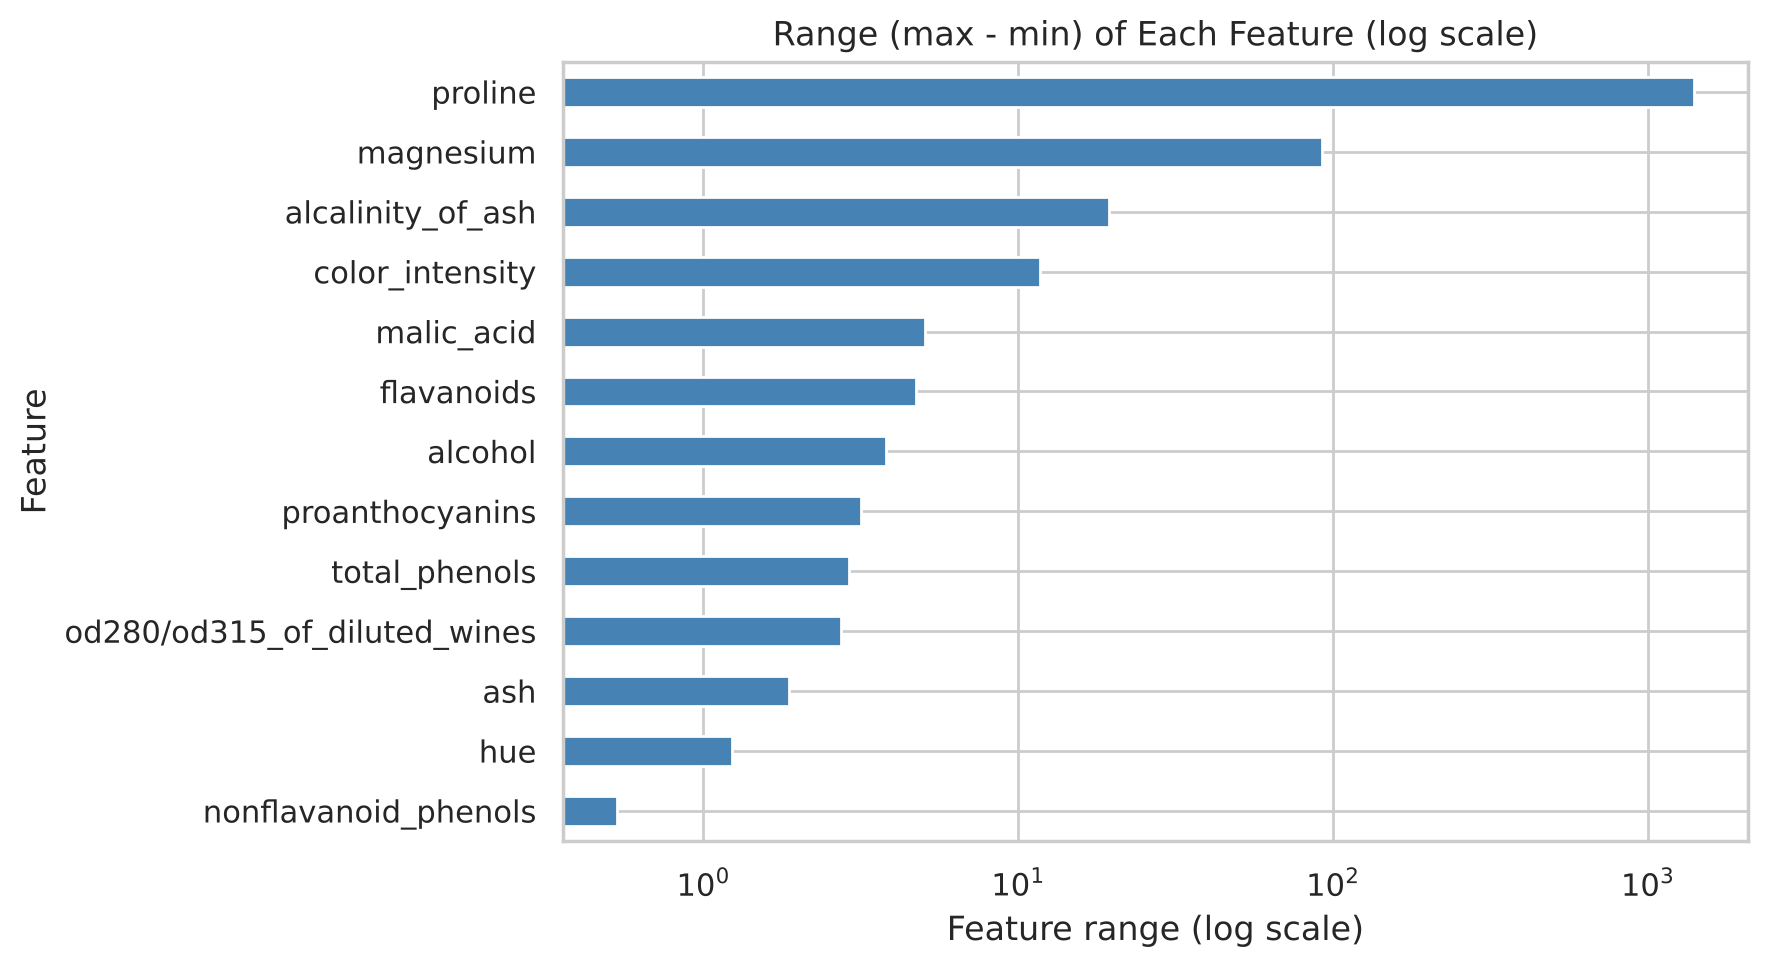

In [6]:
# Visualize the feature scale differences
feature_ranges = (df.drop(columns="target").max() - df.drop(columns="target").min()).sort_values()

fig, ax = plt.subplots(figsize=(9, 5))
feature_ranges.plot(kind="barh", ax=ax, color="steelblue")
ax.set_xscale("log")
ax.set_title("Range (max - min) of Each Feature (log scale)")
ax.set_xlabel("Feature range (log scale)")
ax.set_ylabel("Feature")
plt.tight_layout()
plt.show()

0 (class_0)    59
1 (class_1)    71
2 (class_2)    48


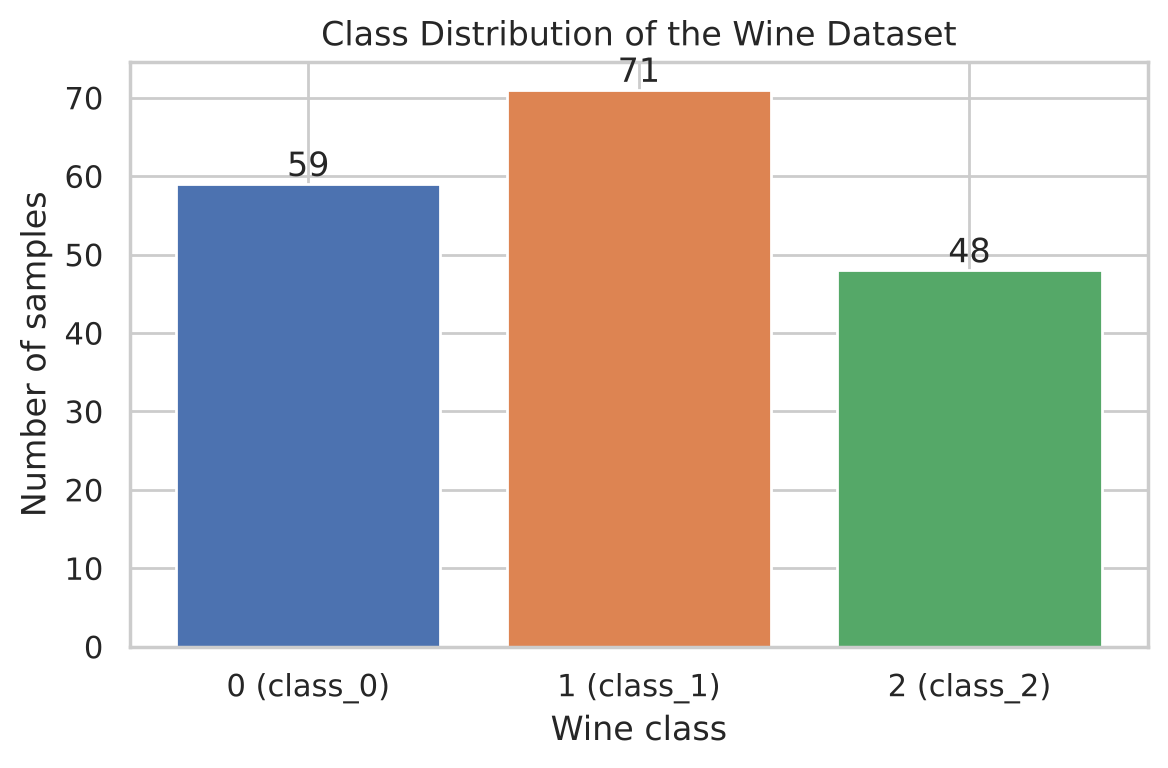

In [7]:
# Class distribution
class_counts = df["target"].value_counts().sort_index()
class_counts.index = [f"{i} ({n})" for i, n in enumerate(wine.target_names)]
print(class_counts.to_string())

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(class_counts.index, class_counts.values, color=["#4C72B0", "#DD8452", "#55A868"])
ax.bar_label(bars)
ax.set_title("Class Distribution of the Wine Dataset")
ax.set_xlabel("Wine class")
ax.set_ylabel("Number of samples")
plt.tight_layout()
plt.show()

**Observation:** The classes are a little uneven (59, 71, and 48 samples), so I used `stratify=y` in the split to keep
the same proportions in the training and test sets.

### 1.4 Train/Test Split (80% / 20%)
I kept the original (unscaled) features for Steps 2 and 3 because the radius values given in the lab are based on the
original units.

In [8]:
X = df.drop(columns="target").values
y = df["target"].values

# 80% training, 20% testing, stratified to preserve class proportions
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

print(f"Training set: {X_train.shape[0]} samples")
print(f"Testing set:  {X_test.shape[0]} samples")
print("Train class counts:", np.bincount(y_train))
print("Test class counts: ", np.bincount(y_test))

Training set: 142 samples
Testing set:  36 samples
Train class counts: [47 57 38]
Test class counts:  [12 14 10]


## Step 2: Implement K-Nearest Neighbors (KNN)

KNN classifies a sample by looking at its k closest training samples and taking a majority vote.

I tested k = 1, 5, 11, 15, and 21. A small k like 1 depends on only one neighbor, so it can be affected by noise.
Larger k values use more neighbors and give smoother predictions. Odd numbers help avoid ties in the vote.

In [9]:
k_values = [1, 5, 11, 15, 21]
knn_results = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)   # default: Euclidean distance, uniform weights
    knn.fit(X_train, y_train)                   # train on the training set
    y_pred = knn.predict(X_test)                # evaluate on the test set
    acc = accuracy_score(y_test, y_pred)
    knn_results.append({"k": k, "accuracy": acc})
    print(f"k = {k:>2}  ->  test accuracy = {acc:.4f}")

knn_df = pd.DataFrame(knn_results)
knn_df

k =  1  ->  test accuracy = 0.7778
k =  5  ->  test accuracy = 0.8056
k = 11  ->  test accuracy = 0.8056
k = 15  ->  test accuracy = 0.8056
k = 21  ->  test accuracy = 0.8056


,k,accuracy
0,1,0.777778
1,5,0.805556
2,11,0.805556
3,15,0.805556
4,21,0.805556


**Results:** k = 1 had the lowest accuracy (77.8%), which makes sense because it only uses one neighbor. Accuracy went
up to 80.6% at k = 5 and stayed the same up to k = 21. So after 5 neighbors, adding more didn't change the predictions.
I picked k = 5 as the best value since it's the smallest k with the highest accuracy. Accuracy stayed around 80%,
likely because `proline` dominates the distance calculation.

## Step 3: Implement Radius Neighbors (RNN)

Radius Neighbors works like KNN, but instead of using a fixed number of neighbors, it uses all training samples within
a certain distance (radius). So the number of neighbors can be different for each point.

I tested radius values of 350, 400, 450, 500, 550, and 600. I also set `outlier_label="most_frequent"` so the model
doesn't give an error if a test point has no neighbors inside the radius. I also counted the average number of
neighbors for each radius to help explain the results.

In [10]:
radius_values = [350, 400, 450, 500, 550, 600]
rnn_results = []

for r in radius_values:
    rnn = RadiusNeighborsClassifier(radius=r, outlier_label="most_frequent")
    rnn.fit(X_train, y_train)
    y_pred = rnn.predict(X_test)
    acc = accuracy_score(y_test, y_pred)

    # How many training neighbors fall inside the radius for each test point?
    neighbors = rnn.radius_neighbors(X_test, return_distance=False)
    counts = np.array([len(n) for n in neighbors])

    rnn_results.append({
        "radius": r,
        "accuracy": acc,
        "avg_neighbors": counts.mean(),
        "test_points_with_no_neighbors": int((counts == 0).sum()),
    })
    print(f"r = {r}  ->  test accuracy = {acc:.4f}   (avg neighbors in radius: {counts.mean():.1f})")

rnn_df = pd.DataFrame(rnn_results)
rnn_df.round(4)

r = 350  ->  test accuracy = 0.7222   (avg neighbors in radius: 80.5)
r = 400  ->  test accuracy = 0.6944   (avg neighbors in radius: 87.9)
r = 450  ->  test accuracy = 0.6944   (avg neighbors in radius: 94.8)
r = 500  ->  test accuracy = 0.6944   (avg neighbors in radius: 100.1)
r = 550  ->  test accuracy = 0.6667   (avg neighbors in radius: 106.0)
r = 600  ->  test accuracy = 0.6667   (avg neighbors in radius: 111.0)


,radius,accuracy,avg_neighbors,test_points_with_no_neighbors
0,350,0.7222,80.5278,0
1,400,0.6944,87.8611,0
2,450,0.6944,94.8333,0
3,500,0.6944,100.0556,0
4,550,0.6667,105.9722,0
5,600,0.6667,110.9722,0


**Results:** The best radius was 350 (72.2% accuracy), and accuracy went down as the radius got bigger, dropping to
66.7% at 550 and 600. Looking at the average neighbors, even r = 350 includes about 80 of the 142 training samples,
and r = 600 includes about 111. With that many neighbors, the model starts predicting the most common class instead of
using the nearby points. No test point ended up with zero neighbors. Based on the trend, a smaller radius might work better.

## Step 4: Visualize and Compare Results

### 4.1 KNN Accuracy vs. k

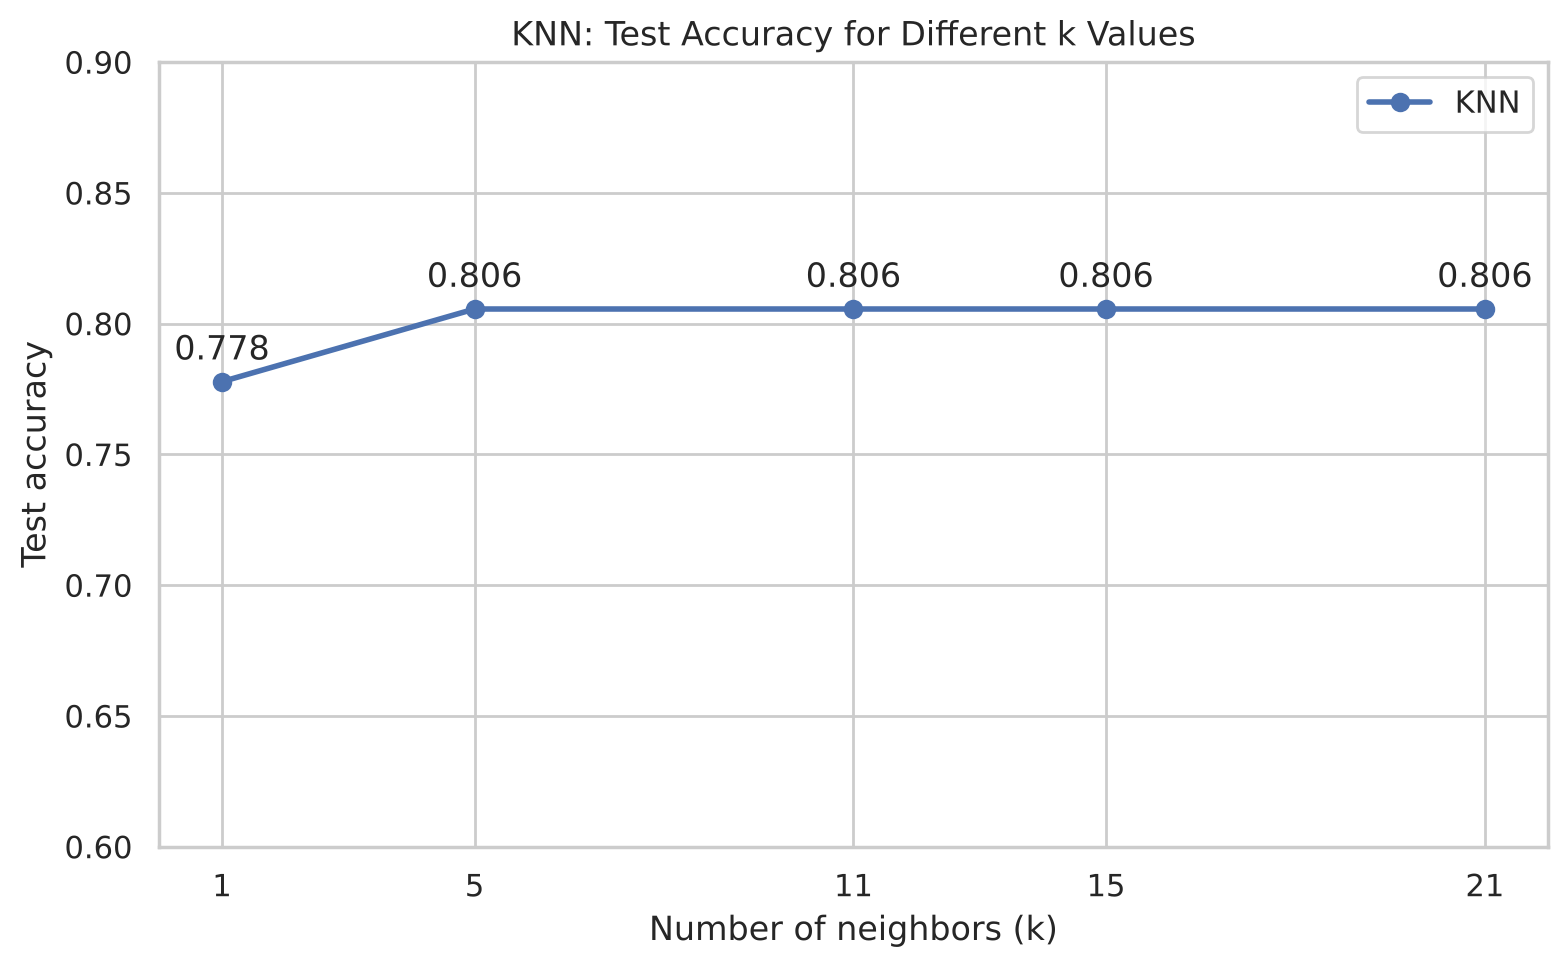

In [11]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(knn_df["k"], knn_df["accuracy"], marker="o", linewidth=2, color="#4C72B0", label="KNN")
for k, acc in zip(knn_df["k"], knn_df["accuracy"]):
    ax.annotate(f"{acc:.3f}", (k, acc), textcoords="offset points", xytext=(0, 8), ha="center")
ax.set_title("KNN: Test Accuracy for Different k Values")
ax.set_xlabel("Number of neighbors (k)")
ax.set_ylabel("Test accuracy")
ax.set_xticks(k_values)
ax.set_ylim(0.6, 0.9)
ax.legend()
plt.tight_layout()
plt.show()

### 4.2 RNN Accuracy vs. Radius

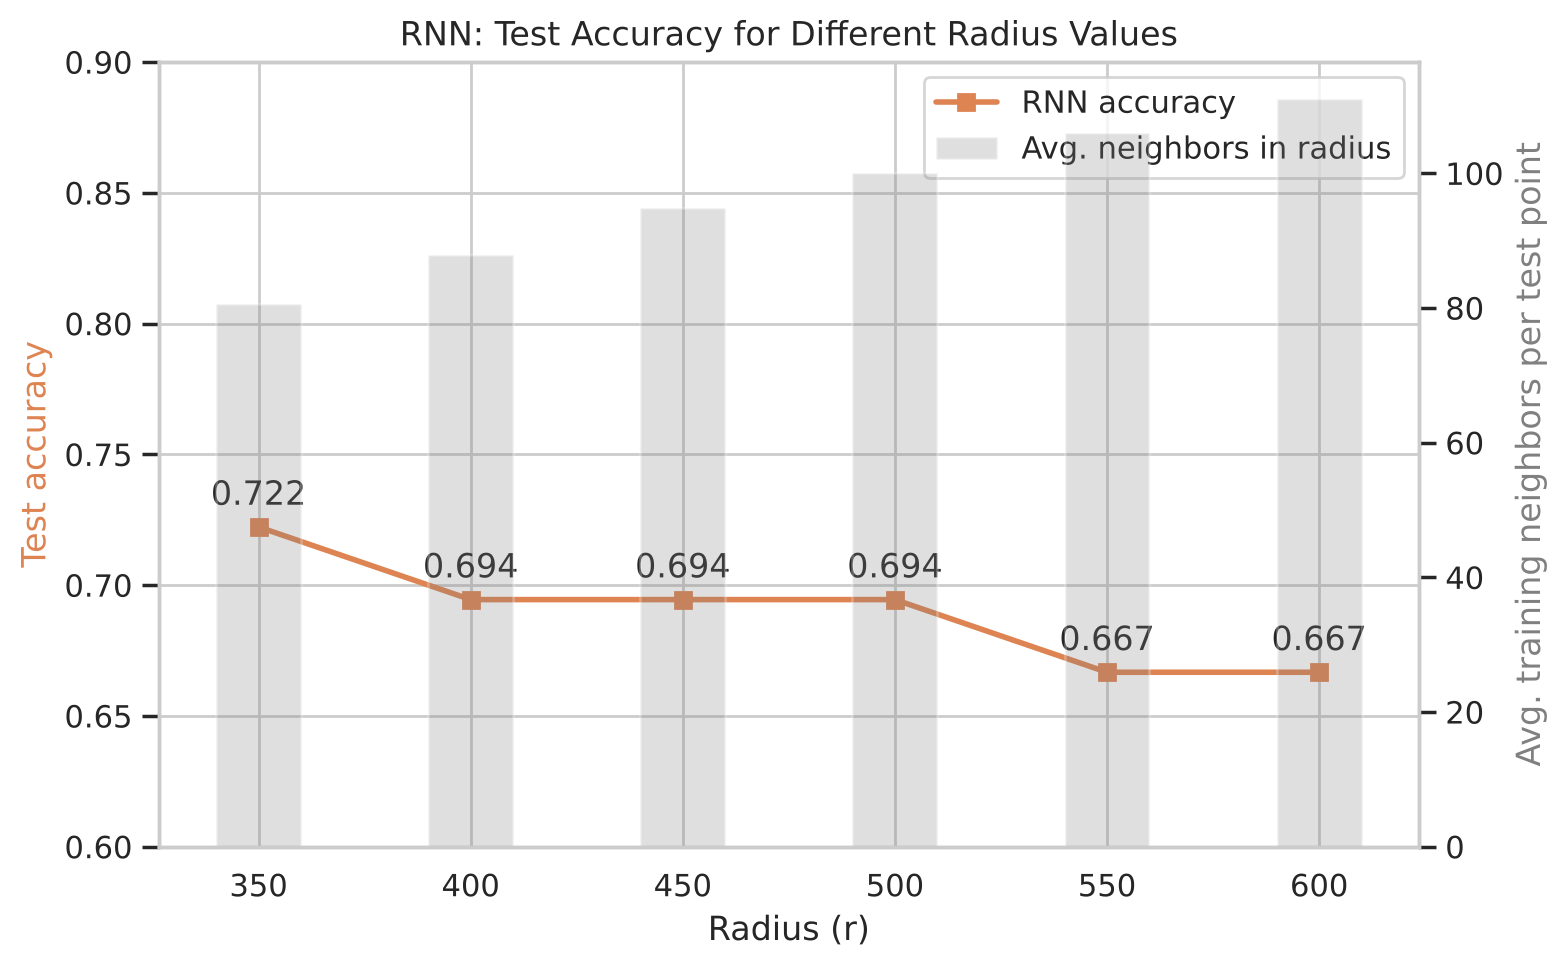

In [12]:
fig, ax1 = plt.subplots(figsize=(8, 5))

# Accuracy on the left axis
ax1.plot(rnn_df["radius"], rnn_df["accuracy"], marker="s", linewidth=2, color="#DD8452", label="RNN accuracy")
for r, acc in zip(rnn_df["radius"], rnn_df["accuracy"]):
    ax1.annotate(f"{acc:.3f}", (r, acc), textcoords="offset points", xytext=(0, 8), ha="center")
ax1.set_xlabel("Radius (r)")
ax1.set_ylabel("Test accuracy", color="#DD8452")
ax1.set_ylim(0.6, 0.9)
ax1.set_xticks(radius_values)

# Average neighbor count on the right axis, to show WHY accuracy falls
ax2 = ax1.twinx()
ax2.bar(rnn_df["radius"], rnn_df["avg_neighbors"], width=20, alpha=0.25, color="gray", label="Avg. neighbors in radius")
ax2.set_ylabel("Avg. training neighbors per test point", color="gray")
ax2.grid(False)

ax1.set_title("RNN: Test Accuracy for Different Radius Values")
lines = ax1.get_legend_handles_labels()[0] + ax2.get_legend_handles_labels()[0]
labels = ax1.get_legend_handles_labels()[1] + ax2.get_legend_handles_labels()[1]
ax1.legend(lines, labels, loc="upper right")
plt.tight_layout()
plt.show()

### 4.3 Comparing KNN and RNN

In [13]:
best_knn = knn_df.loc[knn_df["accuracy"].idxmax()]
best_rnn = rnn_df.loc[rnn_df["accuracy"].idxmax()]

summary = pd.DataFrame({
    "Model": ["KNN", "RNN"],
    "Best parameter": [f"k = {int(best_knn['k'])}", f"r = {int(best_rnn['radius'])}"],
    "Best accuracy": [best_knn["accuracy"], best_rnn["accuracy"]],
    "Worst accuracy": [knn_df["accuracy"].min(), rnn_df["accuracy"].min()],
    "Mean accuracy": [knn_df["accuracy"].mean(), rnn_df["accuracy"].mean()],
}).round(4)
summary

,Model,Best parameter,Best accuracy,Worst accuracy,Mean accuracy
0,KNN,k = 5,0.8056,0.7778,0.8000
1,RNN,r = 350,0.7222,0.6667,0.6898


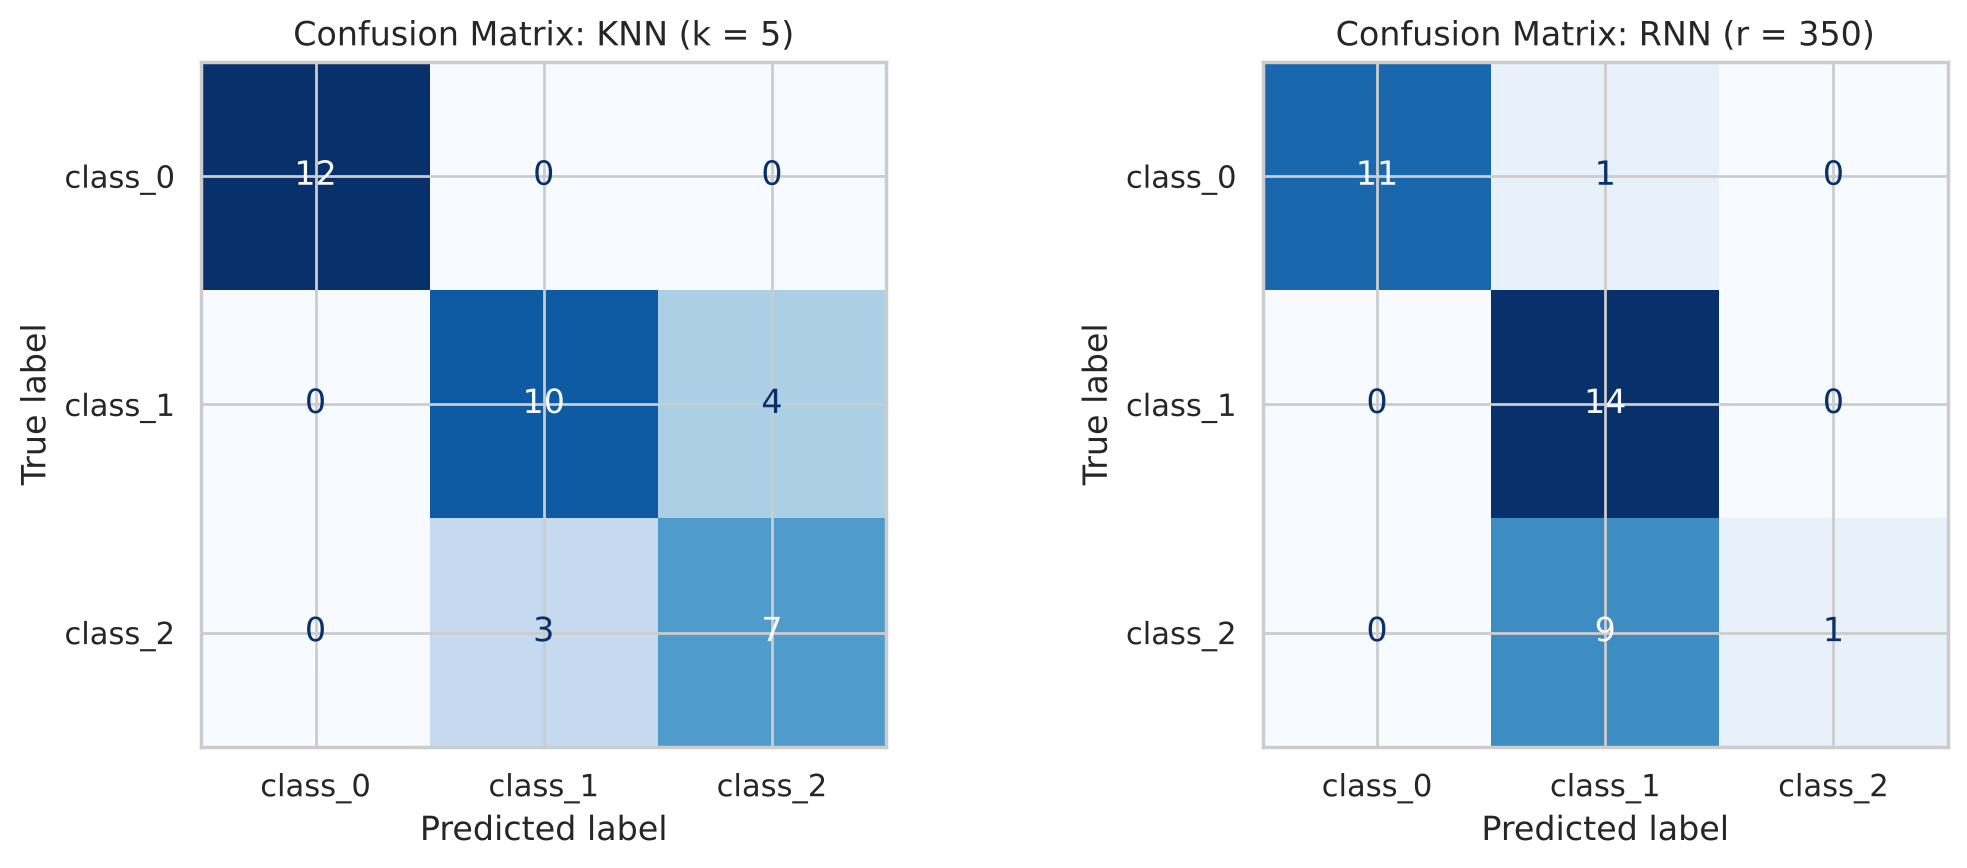

In [14]:
# Confusion matrices for the best configuration of each model
best_knn_model = KNeighborsClassifier(n_neighbors=int(best_knn["k"])).fit(X_train, y_train)
best_rnn_model = RadiusNeighborsClassifier(radius=best_rnn["radius"], outlier_label="most_frequent").fit(X_train, y_train)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, model, title in zip(
    axes,
    [best_knn_model, best_rnn_model],
    [f"KNN (k = {int(best_knn['k'])})", f"RNN (r = {int(best_rnn['radius'])})"],
):
    cm = confusion_matrix(y_test, model.predict(X_test))
    ConfusionMatrixDisplay(cm, display_labels=wine.target_names).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"Confusion Matrix: {title}")
plt.tight_layout()
plt.show()

**Comparison**

- KNN did better than RNN for every value I tested. Its best accuracy was 80.6% compared to 72.2% for RNN, and even
  KNN's lowest score (77.8%) was higher than RNN's best.
- KNN improved when going from 1 to 5 neighbors and then leveled off. RNN got worse as the radius increased because the
  bigger radius included most of the training data.
- From the confusion matrices, both models classified `class_0` correctly almost every time. Most mistakes were between
  `class_1` and `class_2`. RNN predicted 9 out of 10 `class_2` samples as `class_1`, which shows its neighborhoods were
  too large and dominated by `class_1`, the biggest class.

## Conclusions: When Is KNN or RNN Preferable?

For this dataset, the best KNN model was k = 5 (80.6%) and the best RNN model was r = 350 (72.2%).

**KNN might be better when:**
- The data is spread out unevenly, since KNN always uses the same number of neighbors.
- You want a simple parameter to tune. Choosing k is easier than finding the right radius.

**RNN might be better when:**
- The data is scaled and evenly spread, so one radius works well for all points.
- You want to find outliers, since points with no neighbors in the radius can be flagged.

Overall, KNN worked better in this lab. RNN can work well too, but the radius has to be chosen carefully based on the
scale of the data.